# Neural Networks – Breast Cancer Classification with a Multilayer Perceptron

This notebook demonstrates binary classification of breast tumors using an MLP neural network. The target variable is `isBenign`: `0` = malignant (positive class for evaluation), `1` = benign.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

#1. Loading data

In [2]:
# Loading the dataset and defining missing-value markers: "-", " ", and ""
df = pd.read_csv("breast_cancer.csv", na_values=['-', ' ', ''])

display(df.head())
df.info()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,isBenign
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              567 non-null    float64
 1   mean texture             567 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

#2. Replacing the missing values

In [3]:
# Checking for missing values in each feature
print(df.isna().sum())
# Both "mean radius" and "mean texture" have two missing values

mean radius                2
mean texture               2
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
isBenign                   0
dtype: int64


The numerical features `mean radius` and `mean texture` contain a small number of missing values. To choose an imputation strategy, we will examine their distributions using the Shapiro–Wilk test. If the distributions are approximately normal, we consider mean imputation; otherwise, we use median imputation.

In [4]:
# Testing whether the two features follow a normal distribution
p_radius = shapiro(df['mean radius'].dropna())[1]
p_texture = shapiro(df['mean texture'].dropna())[1]

print("p-value for mean radius:", p_radius)
print("p-value for mean texture:", p_texture)

# Both p-values are below 0.05, suggesting non-normal distributions; use median imputation

median_radius = df['mean radius'].median()
print(median_radius)
median_texture = df['mean texture'].median()
print(median_texture)

# The medians are 13.37 and 18.87 for mean radius and mean texture, respectively

# Replacing missing values with the corresponding medians
df['mean radius'] = df['mean radius'].fillna(median_radius)
df['mean texture'] = df['mean texture'].fillna(median_texture)

print(df.isna().sum())
# No missing values remain

p-value for mean radius: 3.792843427944608e-14
p-value for mean texture: 9.007535733256736e-08
13.37
18.87
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
isBenign               

#3. Splitting the dataset into test/train sets

In [5]:
# Splitting the dataset into training (80%) and test (20%) subsets

X = df.drop(columns='isBenign')
y = df['isBenign']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# Standardizing the features using the training-set mean and standard deviation
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [7]:
# Defining the multilayer perceptron classifier
mlp1=MLPClassifier(hidden_layer_sizes=(64,32), max_iter=1000, random_state=42, solver='sgd')

## Neural Network Architecture

The MLP architecture is **30–64–32–1**:

- The input layer contains **30 features**.
- The first hidden layer contains **64 neurons**.
- The second hidden layer contains **32 neurons**.
- The output layer represents a **binary classification** decision using one output unit.

The model uses stochastic gradient descent (`solver="sgd"`) and a maximum of 1,000 training iterations.

#4. Training the neural network model

In [8]:
mlp1.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42,
              solver='sgd')

## How the Neural Network Is Trained

1. **Forward propagation:** Input features pass through the network to produce predictions.
2. **Loss calculation:** Predictions are compared with the true labels to quantify prediction error.
3. **Backpropagation:** Gradients are computed to estimate how the weights and biases contribute to the loss.
4. **Parameter updates:** Stochastic gradient descent updates the weights and biases to reduce the loss.

These steps are repeated during training. The loss curve below illustrates how the training loss changes across iterations.

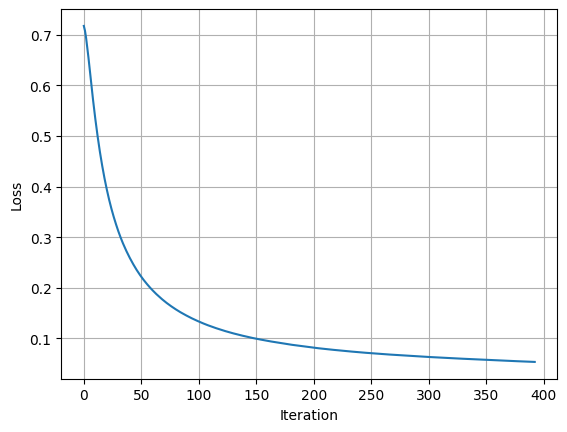

In [9]:
# Showing the training loss over iterations
plt.figure()
plt.plot(mlp1.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid()
plt.show()

In [10]:
y_pred=mlp1.predict(X_test)

#5. Evaluating confusion matrix

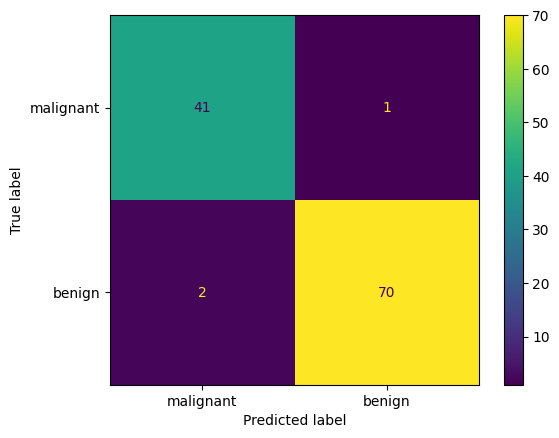

In [11]:
# Displaying the confusion matrix (label order: malignant = 0, benign = 1)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['malignant','benign'])
disp.plot()
plt.show()

## Confusion Matrix Interpretation

For this task, **malignant tumors (`isBenign = 0`) are the positive class**. The confusion matrix is displayed in label order `[0, 1]` (malignant, benign).

- **True positives (TP = 41):** Malignant tumors correctly predicted as malignant.
- **True negatives (TN = 70):** Benign tumors correctly predicted as benign.
- **False positives (FP = 2):** Benign tumors incorrectly predicted as malignant.
- **False negatives (FN = 1):** Malignant tumors incorrectly predicted as benign.

The main diagonal contains the 111 correct predictions, while the off-diagonal cells contain the 3 classification errors. Missing a malignant tumor (a false negative) is especially important in this context.

#6. Classification Evaluation Metrics

Four commonly used metrics are:

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Among tumors predicted as malignant, the proportion that are actually malignant.
- **Recall (sensitivity):** Among truly malignant tumors, the proportion correctly identified as malignant.
- **F1-score:** Harmonic mean of precision and recall, balancing these two metrics.

All precision, recall, and F1-score calculations below use **`pos_label=0`**, because malignant tumors are the positive class in this assignment.

In [12]:
def compute_eval_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=0)
    recall = recall_score(y_true, y_pred, pos_label=0)
    f1 = f1_score(y_true, y_pred, pos_label=0)
    return {
        'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

In [13]:
# Calculating the classification evaluation metrics
mlp1_eval=compute_eval_metrics(y_test, y_pred)
print(mlp1_eval)

{'accuracy': 0.9736842105263158, 'precision': 0.9534883720930233, 'recall': 0.9761904761904762, 'f1': 0.9647058823529412}


## Model Evaluation – Interpretation

**Accuracy (97.37%):** The model correctly classified 111 out of 114 tumor samples, indicating excellent overall classification performance.

**Precision (95.35%):** Among all tumors predicted as malignant, 95.35% were actually malignant. This indicates a low proportion of false positive predictions.

**Recall / Sensitivity (97.62%):** The model correctly identified 41 out of 42 malignant tumors. This is particularly important because failing to detect a malignant tumor could have serious consequences.

**F1-score (96.47%):** The high F1-score indicates a strong balance between precision and recall for the malignant class.

## Overall Conclusion

The Multilayer Perceptron (MLP) classifier achieved excellent performance on the test dataset, with an accuracy of 97.37% and an F1-score of 96.47%. The model correctly identified almost all malignant tumors, with only one false negative and two false positives.

Although these results are promising, additional validation on independent datasets would be necessary before considering the model for real-world medical applications.